In [2]:
# importing important libraries

import numpy as np
import pandas as pd
import seaborn as ss
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.ensemble import RandomForestRegressor

In [3]:
# importing the data set 

dataset = pd.read_csv('DataFiles/gold_regression.csv')

In [4]:
# checkig basic info about the data

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     2290 non-null   object 
 1   SPX      2290 non-null   float64
 2   GLD      2290 non-null   float64
 3   USO      2290 non-null   float64
 4   SLV      2290 non-null   float64
 5   EUR/USD  2290 non-null   float64
dtypes: float64(5), object(1)
memory usage: 107.5+ KB


In [5]:
# by seeing above we can say that there are no missing values present in the data set

dataset.isnull().sum()

Date       0
SPX        0
GLD        0
USO        0
SLV        0
EUR/USD    0
dtype: int64

In [6]:
dataset.isna().sum()

Date       0
SPX        0
GLD        0
USO        0
SLV        0
EUR/USD    0
dtype: int64

In [7]:
# checking any duplicates values present in the dataset

dataset.duplicated().sum()

# By seeing below there are no duplicates values present in the dataset

0

In [8]:
import ydata_profiling

print("Installed sucessfully")

Installed sucessfully


In [ ]:
# checking the distributions of the dataset

from ydata_profiling import ProfileReport
data_profile = ProfileReport(dataset, title="data")
data_profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:00<00:00, 86.28it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

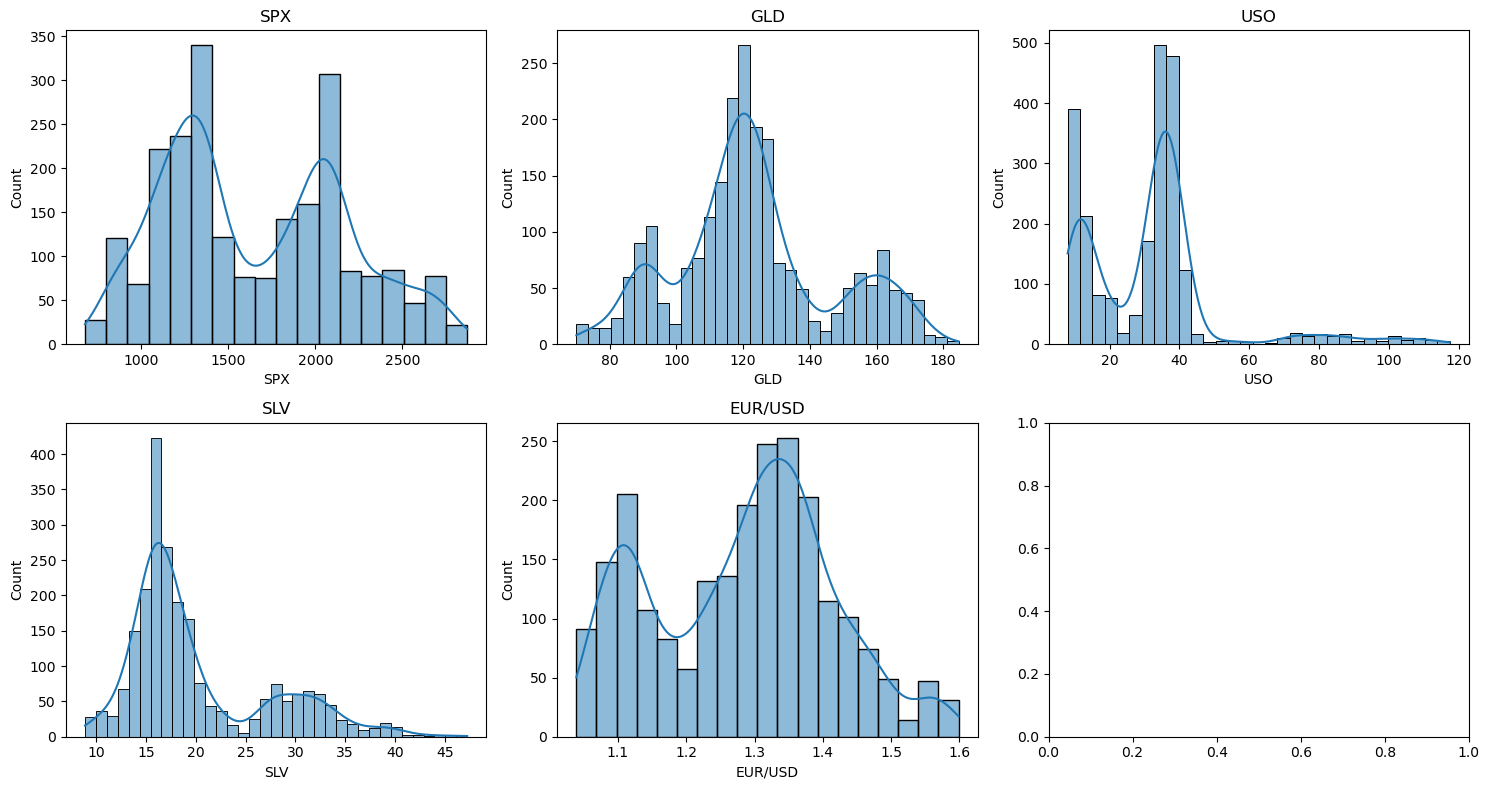

In [30]:

%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

num_cols = dataset.select_dtypes(include=['int64','float64']).columns

fig, axes = plt.subplots(2, 3, figsize=(15,8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(dataset[col], kde=True, ax=axes[i])
    axes[i].set_title(f"{col}")

plt.tight_layout()
plt.show()


In [31]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
SPX,2290.0,1654.315776,519.111540,676.530029,1239.874969,1551.434998,2073.010070,2872.870117
GLD,2290.0,122.732875,23.283346,70.000000,109.725000,120.580002,132.840004,184.589996
USO,2290.0,31.842221,19.523517,7.960000,14.380000,33.869999,37.827501,117.480003
SLV,2290.0,20.084997,7.092566,8.850000,15.570000,17.268500,22.882500,47.259998
EUR/USD,2290.0,1.283653,0.131547,1.039047,1.171313,1.303297,1.369971,1.598798


In [32]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPX      2290 non-null   float64
 1   GLD      2290 non-null   float64
 2   USO      2290 non-null   float64
 3   SLV      2290 non-null   float64
 4   EUR/USD  2290 non-null   float64
dtypes: float64(5)
memory usage: 89.6 KB


In [34]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPX      2290 non-null   float64
 1   GLD      2290 non-null   float64
 2   USO      2290 non-null   float64
 3   SLV      2290 non-null   float64
 4   EUR/USD  2290 non-null   float64
dtypes: float64(5)
memory usage: 89.6 KB


<Axes: >

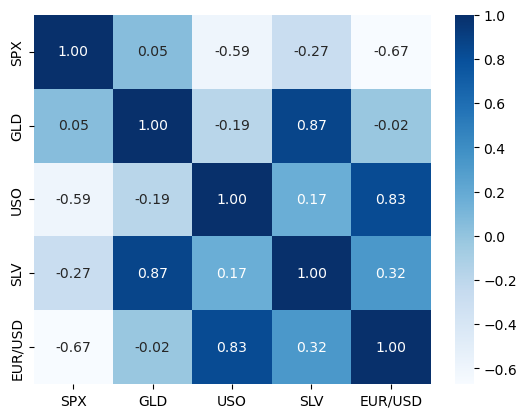

In [35]:
sns.heatmap(dataset.corr(),cmap='Blues',fmt = ".2f",annot=True)

In [36]:
corr_matrix = dataset.corr()

<Axes: >

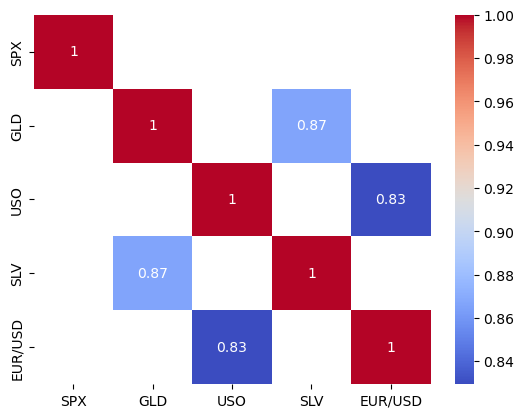

In [37]:
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    mask=np.abs(corr_matrix) < 0.80
)

In [40]:
# splitting the data into dependent and independent vairables

dataset.info()

X = dataset.drop('GLD',axis=1)
y = dataset['GLD']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPX      2290 non-null   float64
 1   GLD      2290 non-null   float64
 2   USO      2290 non-null   float64
 3   SLV      2290 non-null   float64
 4   EUR/USD  2290 non-null   float64
dtypes: float64(5)
memory usage: 89.6 KB


In [42]:
X.shape,y.shape

((2290, 4), (2290,))

In [43]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPX      2290 non-null   float64
 1   USO      2290 non-null   float64
 2   SLV      2290 non-null   float64
 3   EUR/USD  2290 non-null   float64
dtypes: float64(4)
memory usage: 71.7 KB


In [44]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 2290 entries, 0 to 2289
Series name: GLD
Non-Null Count  Dtype  
--------------  -----  
2290 non-null   float64
dtypes: float64(1)
memory usage: 18.0 KB


In [47]:
# train test split 

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=45)

In [48]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((1534, 4), (756, 4), (1534,), (756,))

In [49]:
# Fitting the randomforeset regressor to the data

from sklearn.ensemble import RandomForestRegressor

RFG = RandomForestRegressor(n_estimators=150)

In [50]:
RFG.fit(X_train,y_train)

RandomForestRegressor(n_estimators=150)

In [53]:
# Evaluvation

y_pred = RFG.predict(X_test)

In [58]:
from sklearn.metrics import r2_score

score = r2_score(y_test,y_pred)

print('R2 Score : ',score)

R2 Score :  0.9861118815735286


In [59]:
y_test = list(y_test)

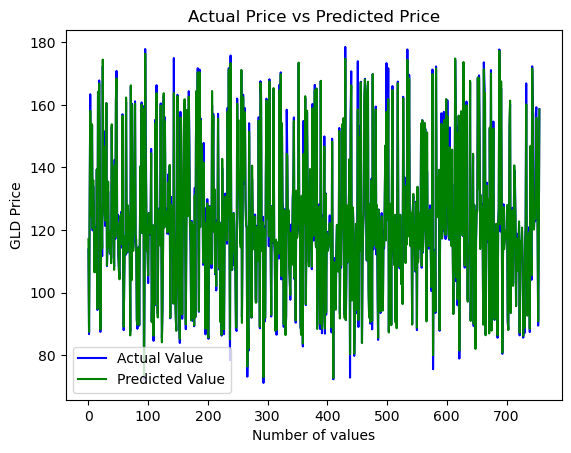

In [62]:
plt.plot(y_test, color='blue', label = 'Actual Value')
plt.plot(y_pred, color='green', label='Predicted Value')
plt.title('Actual Price vs Predicted Price')
plt.xlabel('Number of values')
plt.ylabel('GLD Price')
plt.legend()
plt.show()

In [63]:
# Importing all the regression models.

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [67]:
models = {'DT': DecisionTreeRegressor(),
          'RFR':RandomForestRegressor()
          }

In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluation(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    MAE = mean_absolute_error(y_true, y_pred)
    MSE = mean_squared_error(y_true, y_pred)
    R2  = r2_score(y_true, y_pred)

    return MAE, MSE, R2


In [70]:
model_list = []
acc_score2 = []

for i in range(len(models)):
    model_name = list(models.keys())[i]
    model = list(models.values())[i]

    # Fit
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluation
    MAE, MSE, R2 = evaluation(y_test, y_pred)

    print(model_name)

    model_list.append(model_name)

    print('Model Testing Performance')
    print("MAE :", MAE)
    print("MSE :", MSE)
    print("R2  :", R2)

    acc_score2.append(R2)    

    print('=' * 35, '\n')


DT
Model Testing Performance
MAE : 1.6221641349206346
MSE : 10.3155907810835
R2  : 0.9805403921788768

RFR
Model Testing Performance
MAE : 1.4268582530952394
MSE : 7.341597925947065
R2  : 0.9861506122672796



In [ ]:
dataset.head()

,SPX,GLD,USO,SLV,EUR/USD
0,1447.160034,84.860001,78.470001,15.180,1.471692
1,1447.160034,85.570000,78.370003,15.285,1.474491
2,1411.630005,85.129997,77.309998,15.167,1.475492
3,1416.180054,84.769997,75.500000,15.053,1.468299
4,1390.189941,86.779999,76.059998,15.590,1.557099


In [76]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPX      2290 non-null   float64
 1   USO      2290 non-null   float64
 2   SLV      2290 non-null   float64
 3   EUR/USD  2290 non-null   float64
dtypes: float64(4)
memory usage: 71.7 KB


In [81]:
import warnings

warnings.filterwarnings('ignore')

import numpy as np # 84.860001

new_data = np.array([[1447.16,78.47,15.18,1.4]])

prediction = RFG.predict(new_data)

print("Predicted Gold Price:", prediction[0])


Predicted Gold Price: 85.1227981533333


In [82]:
X1 = dataset.drop('GLD',axis=1)
y1 = dataset['GLD']

In [84]:
# train test split 

from sklearn.model_selection import train_test_split

X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y1, test_size=0.33, random_state=45)

In [85]:
X_train1.shape,X_test1.shape,y_train1.shape,y_test1.shape

((1534, 4), (756, 4), (1534,), (756,))

In [86]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

In [87]:
X_train1 = sc.fit_transform(X_train1)

X_test1 = sc.transform(X_test1)

In [90]:
X_train1.shape

(1534, 4)

In [91]:
X_train1

array([[ 1.97994673, -1.04771089, -0.62715276, -0.41180412],
       [ 1.62017404, -1.13842958, -0.62010047, -0.75823858],
       [ 1.61780628, -1.14105151, -0.60317498, -0.78877098],
       ...,
       [-0.89769316,  0.15732682,  0.35593599,  0.82293265],
       [ 0.93738754, -1.14105151, -0.288643  , -1.22041143],
       [ 0.82456644, -0.84949319, -0.8669305 , -1.34080355]])

In [92]:
X_test1

array([[ 0.6821092 , -0.88095631, -0.6553619 , -1.0457514 ],
       [-0.88680509,  2.77977873, -0.98399846,  1.37786614],
       [ 2.06864288, -0.94230941, -0.54816715, -0.35409949],
       ...,
       [-1.42728931, -0.0188666 , -0.91206513,  0.61023149],
       [-1.08552741,  0.15575377, -0.38596456, -0.05649085],
       [-0.68066888,  0.392776  ,  1.26709127, -0.05037519]])

In [93]:
y_train1

2232    126.080002
2113    120.400002
2112    120.650002
2247    125.720001
797     171.649994
           ...    
580     122.290001
163      72.180000
607     129.470001
1916    126.180000
1667    104.860001
Name: GLD, Length: 1534, dtype: float64

In [94]:
y_test1

1711    113.809998
145      86.709999
2274    127.849998
852     163.399994
2278    125.410004
           ...    
720     142.509995
2200    122.230003
291      89.440002
554     116.650002
882     158.639999
Name: GLD, Length: 756, dtype: float64

In [95]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

In [96]:
models1 = {'LR1':LinearRegression(),
           'Lasso1':Lasso(),
           'Ridge':Ridge(),
           'Svr': SVR(),
           'KNN':KNeighborsRegressor()
}

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluation(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    MAE = mean_absolute_error(y_true, y_pred)
    MSE = mean_squared_error(y_true, y_pred)
    R2  = r2_score(y_true, y_pred)

    return MAE, MSE, R2

In [ ]:
def evaluation1(y_true1,y_pred1):
    y_true1 = np.array(y_true1)
    y_pred1 = np.array(y_pred1)

    MAE1 = mean_absolute_error(y_true1,y_pred1)
    MSE1 = mean_squared_error(y_true1,y_pred1)
    r2_score1 = r2_score(y_true1,y_pred1)

    return MAE1,MSE1,r2_score1

In [120]:
model_list1 = []
acc_score21 = []

for i in range(len(models1)):
    model_name1 = list(models1.keys())[i]
    model1 = list(models1.values())[i]

    # Fit to the model

    model1.fit(X_train1,y_train1)

    # predict the model

    y_pred1 = model1.predict(X_test1)

    # evaluvation

    MAE1,MSE1,r2_score1 = evaluation1(y_test1,y_pred1)

    print(model_name1)

    model_list1.append(model_name1)

    print('Model Testing Performance')
    print("MAE :", MAE1)
    print("MSE :", MSE1)
    print("R2  :", r2_score1)

    acc_score21.append(r2_score1)    

    print('=' * 35, '\n')

    

LR1
Model Testing Performance
MAE : 6.013693232292067
MSE : 66.74656455059376
R2  : 0.8740874859107768

Lasso1
Model Testing Performance
MAE : 6.278932263328546
MSE : 69.4980640064705
R2  : 0.8688969833532711

Ridge
Model Testing Performance
MAE : 6.0162327278631755
MSE : 66.7374607807882
R2  : 0.8741046595069255

Svr
Model Testing Performance
MAE : 3.4352573774529214
MSE : 31.473969217718736
R2  : 0.9406266581770532

KNN
Model Testing Performance
MAE : 1.4350847650793654
MSE : 6.68116067022702
R2  : 0.9873964788646963



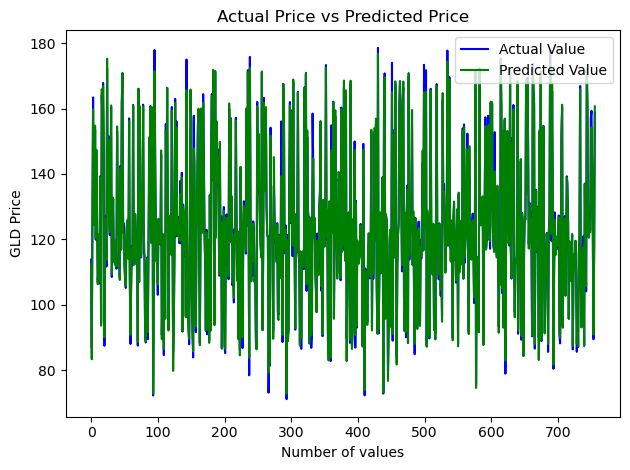

In [124]:
plt.plot(y_test1, color='blue', label = 'Actual Value')
plt.plot(y_pred1, color='green', label='Predicted Value')
plt.title('Actual Price vs Predicted Price')
plt.xlabel('Number of values')
plt.ylabel('GLD Price')
plt.legend(loc = 'upper right')
plt.tight_layout()
plt.show()